# The whole dataset: AF488 cells that crossed the junction, by genotype

**What was run.** `run_dataset.py` (this folder) took every section of the pre-screen table (OASIS) with `Pass` = yes, except those whose `Shape` is `Separated` (two organoids that never fused have no junction): 708 sections. For each one it

1. **found the junction** between the two organoids with the junction finder's defaults, and filed a QC picture under `junction_QC/ok|check|fail`;
2. took the **bands** the section has — `first` (hand-drawn, where it exists), `second` (a second annotator's), `automatic` (the finder's). The **primary band** is the hand-drawn one where it exists, else the finder's. The band is a 300 µm strip on one side of the line, in the organoid where AF488 is *not* at home;
3. **segmented every nucleus** (Cellpose on AF405) in the tissue within 800 µm of a line, and measured AF488 and AF555 over each nucleus grown by 3 µm;
4. placed each cell: in the band or not, its **signed distance to the line** (µm), and its distance to the tissue edge;
5. called each cell **positive** under three rules, chosen in `notebooks/validation/03_positivity_metrics.ipynb`:
   - **calibrated** — brighter than the band's median + 7 SD, on the channel less its 45 µm local median. *The main rule.*
   - **contrast** — at least 1.5 × its own background ring (3–6 µm out). *The check.*
   - **current** — band median + 3 SD, unfiltered: the rule used so far, which the validation found overcounts about 7-fold.

**Routed** sections are those the finder failed on or the pre-screen marked `Damaged`: on them the automatic line is not trusted, so they are **counted** only where a hand-drawn band exists.

**How to read the numbers.**
- **Crossed ≤ 300 µm per mm** — AF488-positive cells on the side of the line where AF488 is *not* at home, up to 300 µm past it, divided by the length of the line in mm. These are cells that migrated out of the AF488 organoid. Per mm of junction because sections differ in how long a junction they cut; note the finder's line can be much shorter than a hand-drawn one, so per-mm counts from the two kinds of band are compared separately in section 3.
- **Band %** — the share of the band's cells that are AF488-positive; **band per mm²** — positive cells per mm² of band.
- **Unit.** A *sample* is one section; sections on one slide may come from the same assembloid, so every comparison is also made on **slide means**, and the mixed model treats slide as a random effect.
- **Tests.** Kruskal-Wallis over all genotypes, then pairwise Mann-Whitney with Holm correction; a linear mixed model on log(1 + count) gives fold changes between genotypes adjusted for experiment (batch).

The run takes about 13 hours and appends one row per section as it goes; this notebook reads whatever has finished, so rerun it when the run completes. Results in the text cells are filled in only after the full run.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import sys
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

ROOT = Path.cwd().resolve()
while not (ROOT / "microscopy_viewer").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("run this notebook from inside the repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "notebooks" / "validation"))

try:
    from count_common import ccc            # Lin's concordance correlation
except Exception as exc:                     # the validation helpers need the image stack; fall back
    print(f"count_common not importable ({exc}); using a local ccc")

    def ccc(a, b):
        a, b = np.asarray(a, float), np.asarray(b, float)
        ok = np.isfinite(a) & np.isfinite(b)
        a, b = a[ok], b[ok]
        if len(a) < 3:
            return np.nan
        return 2 * np.cov(a, b, bias=True)[0, 1] / (a.var() + b.var() + (a.mean() - b.mean()) ** 2)

OUT = Path(r"D:\Slidescanner extracted\dataset_analysis_20261021")
GAP_UM = 2.0           # first µm past the line not counted as crossed (as in the run)
GENOTYPE_COLOURS = {"WT3": "tab:blue", "GD1": "tab:orange", "WT2": "tab:green"}
print("ROOT:", ROOT)
print("OUT: ", OUT)

ROOT: C:\Users\qfavey\Documents\NAPARI-IMS
OUT:  D:\Slidescanner extracted\dataset_analysis_20261021


In [2]:
def read_summary():
    # One row per finished sample; the run appends, so a last half-written line is skipped
    # and a name seen twice keeps its last row.
    rows = []
    for line in (OUT / "summary.jsonl").read_text(encoding="utf-8").splitlines():
        if line.strip():
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError:
                pass
    return pd.DataFrame(rows).drop_duplicates("name", keep="last").reset_index(drop=True)


selected = pd.read_csv(OUT / "samples.csv", encoding="utf-8-sig")
DESIGN = ["Genotype", "Experiment", "Slide", "slide", "Shape", "Ripped", "Folded", "Quality"]
raw = read_summary()
# The design comes from the selection (a crashed row carries none of it).
summary = selected[["name", *DESIGN]].merge(raw.drop(columns=[c for c in DESIGN if c in raw]), on="name", how="inner")
summary["error"] = summary["error"].fillna("").astype(str)
for flag in ("routed", "counted"):
    summary[flag] = summary[flag].fillna(False).astype(bool) if flag in summary else False
summary["Experiment"] = summary["Experiment"].astype(str)
LABEL = summary["label channel"].dropna().mode().iloc[0] if "label channel" in summary and summary["label channel"].notna().any() else "AF488"
GENOTYPES = sorted(summary["Genotype"].dropna().unique())
print(f"{len(selected)} selected; {len(summary)} finished; label channel {LABEL}; genotypes {GENOTYPES}")

708 selected; 708 finished; label channel AF488; genotypes ['GD1', 'WT3']


## 1. Progress and QC

How far the run has come, what the junction finder made of each section, and which sections are counted. **Errored** sections are those with an error message: `crashed: …` (an exception — rerun with `--retry`), `no junction: …` (none found and none drawn) or `no cells found`. **Missing** are selected sections not yet in the summary (still to run, or the run stopped).

In [3]:
crashed = summary["error"].str.startswith("crashed")
errored = summary["error"] != ""
progress = pd.Series({
    "selected": len(selected),
    "file missing on disk": int((~selected["exists"]).sum()) if "exists" in selected else 0,
    "finished": len(summary),
    "errored (any)": int(errored.sum()),
    "  of them crashed": int(crashed.sum()),
    "not yet run": len(selected) - len(summary),
    "with cells measured": int(summary.get("cells measured", pd.Series(dtype=float)).notna().sum()),
    "counted": int(summary["counted"].sum()),
    "counted, not routed": int((summary["counted"] & ~summary["routed"]).sum()),
}, name="sections")
print(progress.to_string())

selected                708
file missing on disk      0
finished                708
errored (any)            21
  of them crashed         0
not yet run               0
with cells measured     687
counted                 615
counted, not routed     611


In [4]:
def counts(column):
    return summary[column].fillna("(none)").replace("", "(none)").value_counts()

print("junction status:\n" + counts("status").to_string(), "\n")
print("routed (finder failed or Damaged):\n" + summary["routed"].value_counts().to_string(), "\n")
print("primary band (first = hand-drawn):\n" + counts("primary band").to_string(), "\n")
print("bands present:\n" + counts("bands").to_string(), "\n")
print("routed × primary band × counted:")
print(pd.crosstab([summary["routed"], summary["primary band"].fillna("")], summary["counted"]).to_string())

junction status:
status
check    479
ok       207
fail      22 

routed (finder failed or Damaged):
routed
False    611
True      97 

primary band (first = hand-drawn):
primary band
automatic    660
first         27
(none)        21 

bands present:
bands
automatic                 659
first,second,automatic     24
(none)                     21
first,automatic             2
second,automatic            1
first,second                1 

routed × primary band × counted:
counted              False  True 
routed primary band              
False  automatic         0    588
       first             0     23
True                    21      0
       automatic        72      0
       first             0      4


In [5]:
by_design = pd.DataFrame({
    "selected": selected.assign(Experiment=selected["Experiment"].astype(str)).groupby(["Genotype", "Experiment"]).size(),
    "finished": summary.groupby(["Genotype", "Experiment"]).size(),
    "errored": summary[errored].groupby(["Genotype", "Experiment"]).size(),
    "routed": summary[summary["routed"]].groupby(["Genotype", "Experiment"]).size(),
    "hand-drawn": summary[summary["primary band"] == "first"].groupby(["Genotype", "Experiment"]).size(),
    "counted": summary[summary["counted"]].groupby(["Genotype", "Experiment"]).size(),
    "slides counted": summary[summary["counted"]].groupby(["Genotype", "Experiment"])["slide"].nunique(),
}).fillna(0).astype(int)
by_design.loc[("all", ""), :] = by_design.sum()
print(by_design.astype(int).to_string())

                     selected  finished  errored  routed  hand-drawn  counted  slides counted
Genotype Experiment                                                                          
GD1      10               122       122        6      14           7      109               6
         8                122       122        8      23           4      100               6
         9                118       118        3      11           4      107               7
WT3      10               123       123        2      20           6      105               6
         8                 89        89        1      12           2       77               5
         9                134       134        1      17           4      117               8
all                       708       708       21      97          27      615              38


In [6]:
errors = summary.loc[errored, ["name", "Genotype", "Experiment", "status", "error"]].copy()
errors["error"] = errors["error"].str.slice(0, 90)
print(f"{len(errors)} sections with an error")
if len(errors):
    print(errors.to_string(index=False))

21 sections with an error
                              name Genotype Experiment status                                  error
2025_09_26_Asssembloid_021-020_s11      WT3          8   fail no junction: none found and none drawn
 2025_09_26_Asssembloid_028-027_s5      WT3          9   fail no junction: none found and none drawn
2025_09_26_Asssembloid_032-031_s11      WT3         10   fail no junction: none found and none drawn
 2025_09_26_Asssembloid_032-031_s9      WT3         10   fail no junction: none found and none drawn
2025_09_26_Asssembloid_038-037_s15      GD1          8   fail no junction: none found and none drawn
2025_09_26_Asssembloid_038-037_s16      GD1          8   fail no junction: none found and none drawn
2025_09_26_Asssembloid_042-041_s15      GD1          8   fail no junction: none found and none drawn
2025_09_26_Asssembloid_042-041_s16      GD1          8   fail no junction: none found and none drawn
2025_09_26_Asssembloid_042-041_s23      GD1          8   fail no 

In [7]:
print("QC pictures (open the folders to look):")
for folder in ["junction_QC/ok", "junction_QC/check", "junction_QC/fail", "count_QC/kept", "count_QC/routed"]:
    path = OUT / folder
    n = len(list(path.glob("*.png"))) if path.exists() else 0
    print(f"  {n:4d}  {path}")
print(f"  run log: {OUT / 'run.log'}")

QC pictures (open the folders to look):
   204  D:\Slidescanner extracted\dataset_analysis_20261021\junction_QC\ok
   482  D:\Slidescanner extracted\dataset_analysis_20261021\junction_QC\check
    22  D:\Slidescanner extracted\dataset_analysis_20261021\junction_QC\fail
   611  D:\Slidescanner extracted\dataset_analysis_20261021\count_QC\kept
    76  D:\Slidescanner extracted\dataset_analysis_20261021\count_QC\routed
  run log: D:\Slidescanner extracted\dataset_analysis_20261021\run.log


In [8]:
timing = summary[["cells measured", "seconds", "segment s", "tiles"]].apply(pd.to_numeric, errors="coerce")
print(timing.describe(percentiles=[0.1, 0.5, 0.9]).T.round(1).to_string())
left = len(selected) - len(summary)
print(f"\ncells measured in all: {timing['cells measured'].sum():,.0f}; "
      f"time so far {timing['seconds'].sum() / 3600:.1f} h; "
      f"at the median pace the {left} left take about {left * timing['seconds'].median() / 3600:.1f} h")

                count     mean      std    min      10%      50%      90%      max
cells measured  687.0  32816.8  14258.4  473.0  13133.0  33349.0  50406.8  73440.0
seconds         708.0     72.9     29.0    0.9     37.4     72.0    105.8    253.4
segment s       687.0     67.2     20.1    7.7     40.9     67.4     91.5    123.0
tiles           687.0      7.9      2.1    1.0      5.0      8.0     11.0     14.0

cells measured in all: 22,545,148; time so far 14.3 h; at the median pace the 0 left take about 0.0 h


## 2. Main result: AF488 cells that crossed, by genotype

On **counted** sections (a usable primary band), and again on counted sections **without the routed ones**. Three measures, calibrated rule:

- **crossed ≤ 300 µm per mm** — migrated cells per mm of junction line;
- **band %** — share of the band's cells that are AF488-positive;
- **band per mm²** — positive cells per mm² of band.

Each table gives, per genotype, the number of sections (or slides) and the median; the Kruskal-Wallis p over all genotypes; and for each pair of genotypes the ratio of medians and the Mann-Whitney p after Holm correction (over the pairs of that measure). **Slide level** first averages the sections of each slide — the more honest unit, with fewer of them.

In [9]:
def metric(rule, region, channel=None):
    # Summary column name for a channel, rule and region / normalisation.
    return f"{channel or LABEL} {rule} {region}"

MAIN = {
    "crossed ≤300 /mm": metric("calibrated", "crossed <=300 per mm"),
    "band %": metric("calibrated", "band %"),
    "band /mm²": metric("calibrated", "band per mm2"),
}


def to_slides(frame, columns):
    # Mean of each slide's sections; design columns carried over.
    agg = {c: "mean" for c in columns}
    agg.update({c: "first" for c in ("Genotype", "Experiment") if c in frame})
    out = frame.groupby("slide").agg(agg).reset_index()
    out["n sections"] = frame.groupby("slide").size().values
    return out


def genotype_test(frame, column, by="Genotype"):
    # One row: n and median per group, Kruskal-Wallis p, pairwise ratio and Holm-corrected Mann-Whitney p.
    groups = sorted(frame[by].dropna().unique())
    parts = {g: pd.to_numeric(frame.loc[frame[by] == g, column], errors="coerce").dropna() for g in groups}
    row = {"n": " / ".join(f"{len(parts[g])}" for g in groups)}
    row.update({f"{g} median": parts[g].median() for g in groups})
    filled = [x for x in parts.values() if len(x) >= 2]
    try:
        row["KW p"] = stats.kruskal(*filled).pvalue if len(filled) >= 2 else np.nan
    except ValueError:                                   # all values identical
        row["KW p"] = np.nan
    pairs, ps = [], []
    for a, b in combinations(groups, 2):
        if len(parts[a]) >= 2 and len(parts[b]) >= 2:
            ma, mb = parts[a].median(), parts[b].median()
            row[f"{b}/{a}"] = mb / ma if ma else np.nan
            pairs.append(f"{b}/{a}")
            ps.append(stats.mannwhitneyu(parts[a], parts[b], alternative="two-sided").pvalue)
    if ps:
        for pair, p in zip(pairs, multipletests(ps, method="holm")[1]):
            row[f"{pair} p(Holm)"] = p
    return row


def genotype_table(frame, columns, unit="sample"):
    data = to_slides(frame, list(columns.values())) if unit == "slide" else frame
    table = pd.DataFrame({name: genotype_test(data, col) for name, col in columns.items()}).T
    return tidy(table)


def tidy(table, digits=3):
    # Round numbers to *digits* significant figures; text, flags and counts like "12 / 9" left alone.
    table = table.copy()
    for c in table.columns:
        if c in ("n", "sections", "Experiment", "name", "slide") or table[c].dtype == bool:
            continue
        values = pd.to_numeric(table[c], errors="coerce")
        if values.notna().sum() == table[c].notna().sum():
            table[c] = values.map(lambda v: float(f"{v:.{digits}g}") if np.isfinite(v) else v)
    return table


counted = summary[summary["counted"]].copy()
SUBSETS = {"counted": counted, "counted, not routed": counted[~counted["routed"]]}
for title, frame in SUBSETS.items():
    for unit in ("sample", "slide"):
        n = len(frame) if unit == "sample" else frame["slide"].nunique()
        print(f"--- {title} — {unit} level ({n} {unit}s)")
        print(genotype_table(frame, MAIN, unit).to_string(), "\n")

--- counted — sample level (615 samples)


                          n  GD1 median  WT3 median          KW p  WT3/GD1  WT3/GD1 p(Holm)
crossed ≤300 /mm  316 / 299       7.660      20.100  4.960000e-16     2.63     4.970000e-16
band %            315 / 299       0.139       0.449  3.620000e-18     3.22     3.620000e-18
band /mm²         315 / 299      28.100      72.100  3.200000e-18     2.56     3.210000e-18 

--- counted — slide level (38 slides)
                        n  GD1 median  WT3 median    KW p  WT3/GD1  WT3/GD1 p(Holm)
crossed ≤300 /mm  19 / 19      13.900       26.00  0.0219     1.86           0.0228
band %            19 / 19       0.244        0.57  0.0160     2.34           0.0167
band /mm²         19 / 19      46.500       94.20  0.0148     2.03           0.0154 

--- counted, not routed — sample level (611 samples)


                          n  GD1 median  WT3 median          KW p  WT3/GD1  WT3/GD1 p(Holm)
crossed ≤300 /mm  314 / 297       7.660      20.100  8.580000e-16     2.63     8.600000e-16
band %            313 / 297       0.139       0.445  7.670000e-18     3.19     7.690000e-18
band /mm²         313 / 297      28.300      72.100  5.800000e-18     2.55     5.820000e-18 

--- counted, not routed — slide level (38 slides)


                        n  GD1 median  WT3 median    KW p  WT3/GD1  WT3/GD1 p(Holm)
crossed ≤300 /mm  19 / 19      13.900       26.00  0.0219     1.86           0.0228
band %            19 / 19       0.244        0.57  0.0188     2.34           0.0195
band /mm²         19 / 19      46.500       94.20  0.0148     2.03           0.0154 



**Mixed model.** `log(1 + y) ~ genotype + experiment`, with a random intercept per slide (sections of one slide are not independent). The genotype coefficients, back-transformed with exp, are **fold changes in (1 + count)** relative to the first genotype in alphabetical order, with 95 % confidence intervals; experiment terms are batch effects. A model that cannot be fitted (too few sections or slides so far) says so.

In [10]:
def mixed_model(frame, column):
    data = frame[["Genotype", "Experiment", "slide"]].copy()
    data["y"] = pd.to_numeric(frame[column], errors="coerce")
    data = data.dropna()
    terms = ["C(Genotype)"] + (["C(Experiment)"] if data["Experiment"].nunique() > 1 else [])
    fit = smf.mixedlm("np.log1p(y) ~ " + " + ".join(terms), data, groups=data["slide"]).fit(reml=True)
    ci = fit.conf_int()
    keep = [k for k in fit.params.index if k.startswith("C(")]
    out = pd.DataFrame({"fold": np.exp(fit.params[keep]), "CI low": np.exp(ci.loc[keep, 0]),
                        "CI high": np.exp(ci.loc[keep, 1]), "p": fit.pvalues[keep]})
    out.index = [k.replace("C(Genotype)[T.", "genotype ").replace("C(Experiment)[T.", "experiment ").rstrip("]")
                 for k in keep]
    return out, len(data), data["slide"].nunique(), fit.converged


for title, frame in SUBSETS.items():
    for name, column in MAIN.items():
        try:
            table, n, n_slides, converged = mixed_model(frame, column)
            print(f"--- {title}: {name} ({n} sections, {n_slides} slides{'' if converged else ', NOT converged'})")
            print(tidy(table).to_string() if len(table) else "  (no terms to estimate: one genotype and one experiment so far)", "\n")
        except Exception as exc:
            print(f"--- {title}: {name}: model not fitted ({type(exc).__name__}: {str(exc)[:80]})\n")

--- counted: crossed ≤300 /mm (615 sections, 38 slides)
              fold  CI low  CI high        p
genotype WT3  1.91   1.190     3.06  0.00708
experiment 8  1.21   0.664     2.21  0.53200
experiment 9  2.15   1.230     3.75  0.00750 

--- counted: band % (614 sections, 38 slides)
              fold  CI low  CI high        p
genotype WT3  1.24   1.090     1.42  0.00158
experiment 8  1.10   0.926     1.31  0.27600
experiment 9  1.26   1.080     1.48  0.00421 



--- counted: band /mm² (614 sections, 38 slides)
              fold  CI low  CI high       p
genotype WT3  1.89   1.100     3.23  0.0206
experiment 8  1.34   0.674     2.65  0.4070
experiment 9  2.28   1.200     4.31  0.0114 



--- counted, not routed: crossed ≤300 /mm (611 sections, 38 slides)
              fold  CI low  CI high        p
genotype WT3  1.90   1.190     3.06  0.00760
experiment 8  1.22   0.667     2.23  0.51700
experiment 9  2.17   1.240     3.81  0.00692 

--- counted, not routed: band % (610 sections, 38 slides)
              fold  CI low  CI high        p
genotype WT3  1.24   1.080     1.42  0.00178
experiment 8  1.10   0.927     1.31  0.27100
experiment 9  1.27   1.080     1.49  0.00400 



--- counted, not routed: band /mm² (610 sections, 38 slides)
              fold  CI low  CI high       p
genotype WT3  1.87   1.080     3.21  0.0242
experiment 8  1.35   0.674     2.69  0.3990
experiment 9  2.30   1.210     4.39  0.0113 



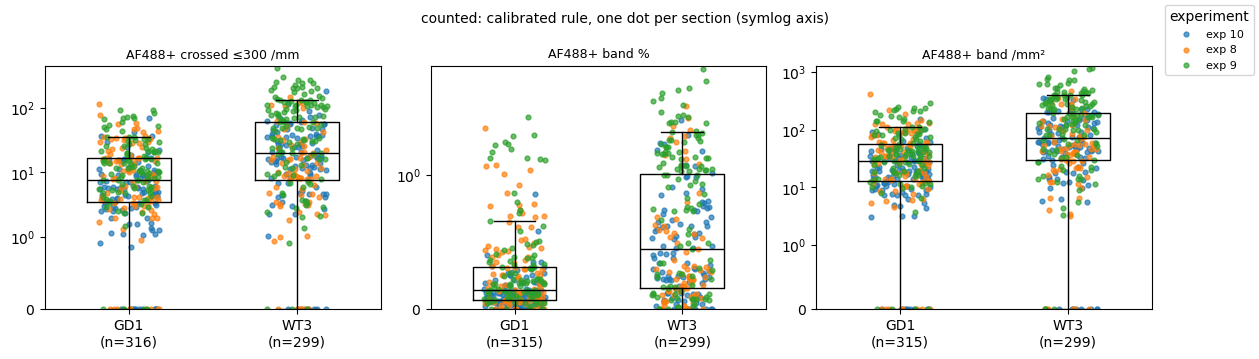

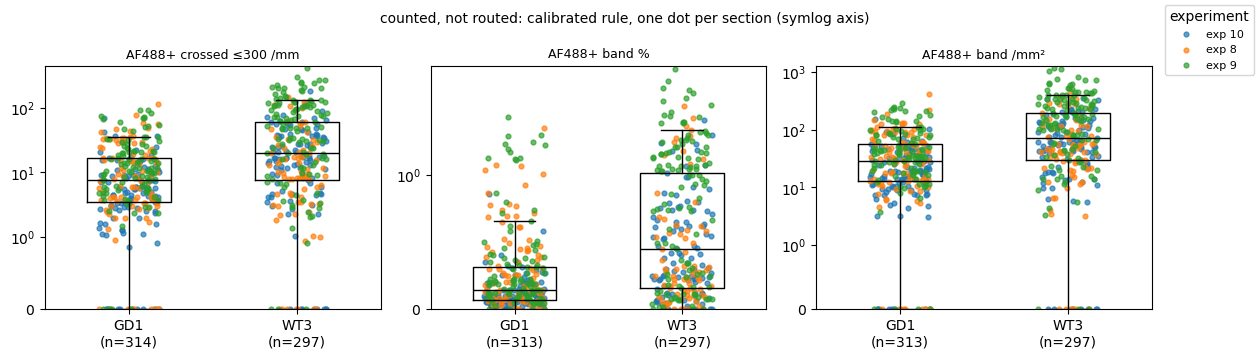

In [11]:
def strip_box(ax, frame, column, title, log=True):
    # One box per genotype, the sections on top as dots coloured by experiment.
    experiments = sorted(frame["Experiment"].dropna().unique())
    colours = dict(zip(experiments, plt.cm.tab10.colors))
    rng = np.random.default_rng(0)
    data = [pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").dropna() for g in GENOTYPES]
    ax.boxplot([d.values if len(d) else [np.nan] for d in data], positions=range(len(GENOTYPES)), widths=0.5,
               showfliers=False, medianprops=dict(color="black"))
    for k, g in enumerate(GENOTYPES):
        part = frame[frame["Genotype"] == g]
        for e in experiments:
            y = pd.to_numeric(part.loc[part["Experiment"] == e, column], errors="coerce").dropna()
            ax.scatter(k + rng.uniform(-0.18, 0.18, len(y)), y, s=12, alpha=0.7, color=colours[e],
                       label=f"exp {e}" if k == 0 else None)
    ax.set_xticks(range(len(GENOTYPES)), [f"{g}\n(n={len(d)})" for g, d in zip(GENOTYPES, data)])
    if log:
        ax.set_yscale("symlog", linthresh=1)
        ax.set_ylim(bottom=0)
    ax.set_title(title, fontsize=9)


for title, frame in SUBSETS.items():
    fig, axes = plt.subplots(1, len(MAIN), figsize=(4.2 * len(MAIN), 3.6))
    for ax, (name, column) in zip(np.atleast_1d(axes), MAIN.items()):
        strip_box(ax, frame, column, f"{LABEL}+ {name}")
    handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", fontsize=8, title="experiment")
    fig.suptitle(f"{title}: calibrated rule, one dot per section (symlog axis)", fontsize=10)
    fig.tight_layout(rect=(0, 0, 0.93, 1))
    plt.show()

## 3. Robustness

Does the genotype comparison hold when the analysis is done differently? Each row is one variant: the number of sections per genotype, the median per genotype, and the Kruskal-Wallis p (sample level; with two genotypes it is equivalent to Mann-Whitney). A real genotype difference should keep its direction across rows; a difference that appears with only one rule or one kind of band is suspect.

**Rules.** The contrast rule is the independent check; the current rule is expected to blur the difference (its positives are mostly background).

In [12]:
def variant_row(frame, column, label):
    row = genotype_test(frame, column)
    keep = {k: v for k, v in row.items() if k == "n" or k.endswith("median") or k == "KW p" or ("/" in k and "p(" not in k)}
    return pd.Series(keep, name=label)


def variants(rows):
    return tidy(pd.DataFrame(rows))


rows = []
for rule in ("calibrated", "contrast", "current"):
    for name, region in (("crossed ≤300 /mm", "crossed <=300 per mm"), ("band %", "band %"), ("band /mm²", "band per mm2")):
        rows.append(variant_row(counted, metric(rule, region), f"{rule}: {name}"))
print("counted sections, three rules:")
print(variants(rows).to_string())

counted sections, three rules:
                                      n  GD1 median  WT3 median          KW p  WT3/GD1
calibrated: crossed ≤300 /mm  316 / 299       7.660      20.100  4.960000e-16     2.63
calibrated: band %            315 / 299       0.139       0.449  3.620000e-18     3.22
calibrated: band /mm²         315 / 299      28.100      72.100  3.200000e-18     2.56
contrast: crossed ≤300 /mm    316 / 299      11.200      15.800  1.070000e-03     1.40
contrast: band %              315 / 299       0.205       0.309  1.680000e-04     1.51
contrast: band /mm²           315 / 299      38.300      56.900  1.600000e-04     1.49
current: crossed ≤300 /mm     316 / 299      89.700     135.000  5.180000e-04     1.50
current: band %               315 / 299       1.850       2.640  1.950000e-04     1.42
current: band /mm²            315 / 299     331.000     489.000  6.600000e-05     1.47


**Kind of band, routed sections, other regions.** Hand-drawn and automatic lines differ in length (the finder's is often shorter), so per-mm counts are compared within each kind. "All finished with a band" adds the routed sections whose only band is the finder's — the ones the validation says not to trust.

In [13]:
main = MAIN["crossed ≤300 /mm"]
with_band = summary[summary["primary band"].fillna("") != ""]
groups = {
    "counted (main)": counted,
    "primary hand-drawn": counted[counted["primary band"] == "first"],
    "primary automatic": counted[counted["primary band"] == "automatic"],
    "counted, not routed": counted[~counted["routed"]],
    "counted, routed only": counted[counted["routed"]],
    "all finished with a band (routed automatic too)": with_band,
    "junction status ok": counted[counted["status"] == "ok"],
    "junction status check": counted[counted["status"] == "check"],
}
rows = [variant_row(frame, main, label) for label, frame in groups.items()]
print(f"{LABEL} calibrated crossed ≤ 300 µm per mm:")
print(variants(rows).to_string(), "\n")
rows = [variant_row(counted, metric("calibrated", r), f"calibrated: {r}")
        for r in ("crossed any per mm", "near+crossed per mm", "band per mm")]
print("other regions (counted):")
print(variants(rows).to_string())

AF488 calibrated crossed ≤ 300 µm per mm:
                                                         n  GD1 median  WT3 median          KW p  WT3/GD1
counted (main)                                   316 / 299        7.66        20.1  4.960000e-16     2.63
primary hand-drawn                                 15 / 12        5.99        22.1  2.480000e-03     3.70
primary automatic                                301 / 287        7.68        20.0  1.460000e-14     2.60
counted, not routed                              314 / 297        7.66        20.1  8.580000e-16     2.63
counted, routed only                                 2 / 2        8.45        35.0  1.210000e-01     4.14
all finished with a band (routed automatic too)  345 / 342        7.98        19.3  2.590000e-13     2.41
junction status ok                                60 / 132       16.50        45.8  5.460000e-08     2.78
junction status check                            255 / 167        6.23        10.4  2.140000e-04     1.67 

ot

In [14]:
# Length of line and band area by kind of band: why per-mm counts are compared within a kind.
geometry = []
for b in ("first", "second", "automatic"):
    col = f"length {b} (um)"
    if col in summary:
        geometry.append(pd.Series({"sections": summary[col].notna().sum(),
                                   "line length median (um)": summary[col].median(),
                                   "band area median (mm2)": summary.get(f"band area {b} (mm2)", pd.Series(dtype=float)).median()},
                                  name=b))
print(tidy(pd.DataFrame(geometry)).to_string())

           sections  line length median (um)  band area median (mm2)
first          27.0                   1150.0                   0.425
second         26.0                   1210.0                   0.450
automatic     686.0                    878.0                   0.299


**Per experiment.** The genotype comparison within each experiment (batch) separately: does the order of the genotypes hold in every batch, or does one batch carry it?

In [15]:
for name, column in MAIN.items():
    rows = [variant_row(frame, column, f"experiment {e}") for e, frame in counted.groupby("Experiment")]
    print(f"{name} (calibrated, counted):")
    print(variants(rows).to_string(), "\n")

crossed ≤300 /mm (calibrated, counted):
                       n  GD1 median  WT3 median          KW p  WT3/GD1
experiment 10  109 / 105        4.96        16.8  6.060000e-11     3.38
experiment 8    100 / 77        7.70         9.3  2.510000e-01     1.21
experiment 9   107 / 117       11.90        55.3  1.120000e-10     4.66 



band % (calibrated, counted):
                       n  GD1 median  WT3 median          KW p  WT3/GD1
experiment 10  109 / 105       0.095       0.381  3.150000e-13     4.01
experiment 8    100 / 77       0.190       0.245  1.440000e-01     1.29
experiment 9   106 / 117       0.200       0.969  5.690000e-09     4.84 



band /mm² (calibrated, counted):
                       n  GD1 median  WT3 median          KW p  WT3/GD1
experiment 10  109 / 105        18.2        56.9  2.570000e-11     3.13
experiment 8    100 / 77        31.3        43.2  5.660000e-02     1.38
experiment 9   106 / 117        41.2       172.0  4.570000e-11     4.17 



**Pre-screen classes.** Do the pre-screen's judgements of the section (Quality, Ripped, Folded) shift the counts? For each class: the median per level, the Kruskal-Wallis p over levels pooled over genotypes, and within each genotype separately (genotypes may differ in how many poor sections they have, which would confound the pooled test).

In [16]:
rows = []
for cls in ("Quality", "Ripped", "Folded"):
    frame = counted.assign(**{cls: counted[cls].fillna("(none)").astype(str)})
    row = genotype_test(frame, main, by=cls)
    medians = frame.groupby(cls)[main].agg(["median", "size"])
    out = {"median per level (n)": "; ".join(f"{lv} {m:.3g} ({int(n)})" for lv, (m, n) in medians.iterrows()),
           "KW p pooled": row["KW p"]}
    for g in GENOTYPES:
        out[f"KW p in {g}"] = genotype_test(frame[frame["Genotype"] == g], main, by=cls)["KW p"]
    rows.append(pd.Series(out, name=cls))
print(f"{LABEL} calibrated crossed ≤ 300 µm per mm, by pre-screen class (counted sections):")
print(tidy(pd.DataFrame(rows)).to_string())

AF488 calibrated crossed ≤ 300 µm per mm, by pre-screen class (counted sections):
                                        median per level (n)  KW p pooled  KW p in GD1  KW p in WT3
Quality  Bad 25.9 (70); Good 10.4 (326); Moderate 11.8 (219)       0.0132       0.0234        0.433
Ripped       no 11.7 (404); review 11.3 (40); yes 11.7 (171)       0.8180       0.8830        0.484
Folded       no 11.8 (425); review 9.44 (31); yes 11.9 (159)       0.4500       0.3340        0.372


## 4. Where the cells are

From the cell tables (`cells/<name>.parquet`) of the counted sections, primary band only. Each section's distance axis is **oriented so that AF488's home organoid is negative**: 0 is the line, + is the organoid AF488 is not at home in (where the band lies, and where any AF488-positive cell has crossed). Cells beyond either end of the line, which have no side, are left out.

- **Profile.** % of cells AF488-positive (calibrated) in 25 µm bins from −600 to +600 µm, per section (bins with fewer than 20 cells left out), then the median over the sections of each genotype. Expect a high plateau on the − side (the labelled organoid), a drop at 0, and a tail on the + side: the migrants.
- **Along the surface?** Median distance to the tissue edge of the crossed AF488-positive cells against that of all cells past the line, per section. If migrants travel along the tissue surface, theirs is smaller.
- **Migration depth.** Median (and 90th percentile) distance past the line of the crossed positive cells, per section.

Files still being written are skipped and re-read on the next run.

In [17]:
BINS = np.arange(-600, 601, 25)
CENTRES = (BINS[:-1] + BINS[1:]) / 2
POS = f"{LABEL} positive calibrated"
HOME = f"{LABEL} home on band side"

profiles, places, skipped = {}, [], []
for _, row in counted.iterrows():
    target = OUT / "cells" / f"{row['name']}.parquet"
    band = row["primary band"]
    cols = [f"in {band}", f"from {band} (um)", f"beside {band}", "edge (um)", POS]
    try:
        cells = pq.read_table(target, columns=cols).to_pandas()
    except Exception as exc:
        skipped.append((row["name"], type(exc).__name__))
        continue
    home_band = bool(row.get(HOME)) if pd.notna(row.get(HOME)) else False
    d = cells[f"from {band} (um)"].to_numpy(float) * (-1.0 if home_band else 1.0)   # + = away from AF488 home
    beside = cells[f"beside {band}"].to_numpy(bool)
    pos = cells[POS].to_numpy(bool)
    edge = cells["edge (um)"].to_numpy(float)
    every, _ = np.histogram(d[beside], BINS)
    hits, _ = np.histogram(d[beside & pos], BINS)
    profiles[row["name"]] = np.where(every >= 20, 100 * hits / np.maximum(every, 1), np.nan)
    past = beside & (d > GAP_UM)
    crossed = past & pos
    places.append({"name": row["name"], "Genotype": row["Genotype"], "Experiment": row["Experiment"], "slide": row["slide"],
                   "cells past line": int(past.sum()), "crossed positives": int(crossed.sum()),
                   "edge, all past (um)": np.median(edge[past]) if past.any() else np.nan,
                   "edge, crossed + (um)": np.median(edge[crossed]) if crossed.any() else np.nan,
                   "depth median (um)": np.median(d[crossed]) if crossed.any() else np.nan,
                   "depth 90th (um)": np.percentile(d[crossed], 90) if crossed.any() else np.nan})
places = pd.DataFrame(places)
print(f"cell tables read: {len(profiles)} of {len(counted)} counted sections; skipped {len(skipped)}"
      + (f": {skipped[:5]}" if skipped else ""))

cell tables read: 615 of 615 counted sections; skipped 0


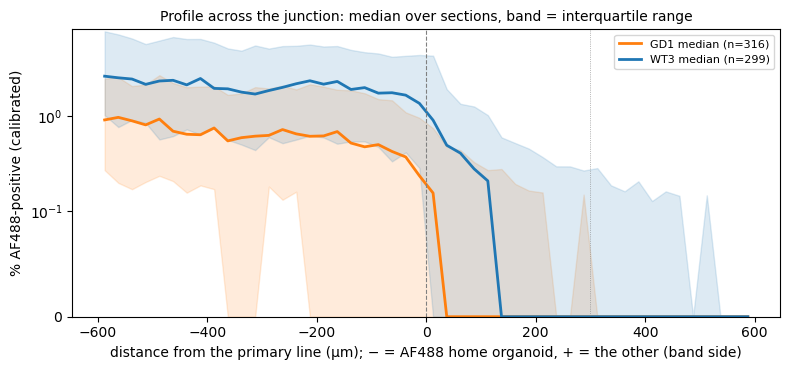

% positive, median over sections of each section's mean over the range:
     home −300…−50 µm  past +50…+300 µm  past +300…+600 µm
GD1             0.709             0.122             0.0398
WT3             2.160             0.283             0.0707


In [18]:
profile = pd.DataFrame(profiles, index=CENTRES).T
profile["Genotype"] = counted.set_index("name").loc[profile.index, "Genotype"]
fig, ax = plt.subplots(figsize=(8, 3.8))
for g, part in profile.groupby("Genotype"):
    values = part.drop(columns="Genotype")
    ax.plot(CENTRES, values.median(), color=GENOTYPE_COLOURS.get(g), lw=2, label=f"{g} median (n={len(part)})")
    ax.fill_between(CENTRES, values.quantile(0.25), values.quantile(0.75), color=GENOTYPE_COLOURS.get(g), alpha=0.15)
ax.axvline(0, color="grey", lw=0.8, ls="--")
ax.axvline(300, color="grey", lw=0.5, ls=":")
ax.set_yscale("symlog", linthresh=0.1)
ax.set_ylim(bottom=0)
ax.set_xlabel(f"distance from the primary line (µm); − = {LABEL} home organoid, + = the other (band side)")
ax.set_ylabel(f"% {LABEL}-positive (calibrated)")
ax.set_title("Profile across the junction: median over sections, band = interquartile range", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

steps = {}
for g, part in profile.groupby("Genotype"):
    values = part.drop(columns="Genotype")
    steps[g] = {"home −300…−50 µm": values.loc[:, (CENTRES > -300) & (CENTRES < -50)].mean(axis=1).median(),
                "past +50…+300 µm": values.loc[:, (CENTRES > 50) & (CENTRES < 300)].mean(axis=1).median(),
                "past +300…+600 µm": values.loc[:, CENTRES > 300].mean(axis=1).median()}
print("% positive, median over sections of each section's mean over the range:")
print(tidy(pd.DataFrame(steps).T).to_string())

In [19]:
pairs = places.dropna(subset=["edge, all past (um)", "edge, crossed + (um)"])
rows = {}
for g, part in pairs.groupby("Genotype"):
    diff = part["edge, crossed + (um)"] - part["edge, all past (um)"]
    try:
        p = stats.wilcoxon(diff).pvalue if len(diff) >= 3 else np.nan
    except ValueError:
        p = np.nan
    rows[g] = {"sections": len(part), "edge, all past (median um)": part["edge, all past (um)"].median(),
               "edge, crossed + (median um)": part["edge, crossed + (um)"].median(),
               "crossed + nearer edge in": f"{int((diff < 0).sum())}/{len(part)}", "Wilcoxon p": p}
print("Distance to the tissue edge: crossed AF488-positive cells vs all cells past the line (per-section medians):")
print(tidy(pd.DataFrame(rows).T).to_string(), "\n")

print("Migration depth of crossed positive cells (per-section median and 90th percentile, µm):")
depth = pd.DataFrame({c: genotype_test(places, c) for c in ("depth median (um)", "depth 90th (um)")}).T
print(tidy(depth).to_string())
print("\n(sample level; slide level:)")
print(tidy(pd.DataFrame({c: genotype_test(to_slides(places, [c]), c) for c in ("depth median (um)",)}).T).to_string())

Distance to the tissue edge: crossed AF488-positive cells vs all cells past the line (per-section medians):
    sections  edge, all past (median um)  edge, crossed + (median um) crossed + nearer edge in    Wilcoxon p
GD1      296                       211.0                        193.0                  163/296  1.530000e-01
WT3      288                       234.0                        161.0                  213/288  4.910000e-19 

Migration depth of crossed positive cells (per-section median and 90th percentile, µm):
                           n  GD1 median  WT3 median     KW p  WT3/GD1  WT3/GD1 p(Holm)
depth median (um)  296 / 288       157.0       129.0  0.00972    0.823          0.00973
depth 90th (um)    296 / 288       357.0       367.0  0.89600    1.030          0.89600

(sample level; slide level:)


                         n  GD1 median  WT3 median   KW p  WT3/GD1  WT3/GD1 p(Holm)
depth median (um)  19 / 19       200.0       204.0  0.422     1.02            0.431

## 5. Band choice

On sections with more than one band, the calibrated rule was also applied to each other band (with that band's own cells setting the threshold and that band's line placing the cells). Here the primary band's counts against each other band's: **CCC** (Lin's concordance; 1 = identical) and a **Bland-Altman** summary — mean difference (other − primary) and the 95 % limits of agreement. Band counts are converted to per mm² of each band so that bands of different size compare. A large disagreement means the count depends on who (or what) drew the band.

In [20]:
rows = []
multi = summary[summary["counted"] & (summary["bands"].fillna("").str.count(",") >= 1)]
for other in ("second", "automatic", "first"):
    for name, prim_col, other_col, area in (
            ("band /mm²", metric("calibrated", "band"), f"{LABEL} calibrated band [{other}]", True),
            ("crossed ≤300 /mm", metric("calibrated", "crossed <=300 per mm"), f"{LABEL} calibrated crossed <=300 [{other}] per mm", False)):
        if other_col not in multi:
            continue
        part = multi[multi[other_col].notna()]
        for primary, sub in part.groupby("primary band"):
            a = pd.to_numeric(sub[prim_col], errors="coerce")
            b = pd.to_numeric(sub[other_col], errors="coerce")
            if area:
                a = a / sub[f"band area {primary} (mm2)"]
                b = b / sub[f"band area {other} (mm2)"]
            ok = a.notna() & b.notna() & np.isfinite(a) & np.isfinite(b)
            a, b = a[ok], b[ok]
            diff = b - a
            rows.append(pd.Series({"sections": len(a), "primary median": a.median(), "other median": b.median(),
                                   "CCC": ccc(a, b), "mean diff": diff.mean(),
                                   "LoA low": diff.mean() - 1.96 * diff.std(), "LoA high": diff.mean() + 1.96 * diff.std(),
                                   "Spearman": stats.spearmanr(a, b)[0] if len(a) >= 3 else np.nan},
                                  name=f"{name}: {primary} vs {other}"))
print(f"{len(multi)} counted sections with more than one band")
if rows:
    print(tidy(pd.DataFrame(rows)).to_string())

28 counted sections with more than one band
                                       sections  primary median  other median    CCC  mean diff  LoA low  LoA high  Spearman
band /mm²: automatic vs second              1.0           129.0         87.30    NaN    -42.000      NaN       NaN       NaN
band /mm²: first vs second                 25.0            33.7         28.70  0.963     -5.360    -42.0      31.3     0.910
crossed ≤300 /mm: automatic vs second       1.0            16.7         36.70    NaN     20.000      NaN       NaN       NaN
crossed ≤300 /mm: first vs second          25.0            11.2          8.96  0.956     -3.810    -19.6      12.0     0.889
band /mm²: first vs automatic              26.0            50.9         40.70  0.904      9.680    -58.9      78.3     0.830
crossed ≤300 /mm: first vs automatic       26.0            15.7         13.10  0.916     -0.556    -25.9      24.7     0.794


## 6. Per-sample table

One row per finished section: design, junction status, whether routed and counted, the primary band and its line length, and the key AF488 counts under the three rules. Written to `per_sample_table.csv` in the output folder (open in a spreadsheet to sort and filter); the sections with the most crossed cells are shown below.

In [21]:
KEY = {
    "name": "name", "Genotype": "Genotype", "Experiment": "Experiment", "slide": "slide",
    "Quality": "Quality", "Ripped": "Ripped", "Folded": "Folded", "Shape": "Shape",
    "status": "status", "flags": "flags", "routed": "routed", "counted": "counted", "bands": "bands",
    "primary band": "primary band", "error": "error", "cells measured": "cells measured",
}
table = summary[[c for c in KEY if c in summary]].copy()
table["line length (um)"] = [r.get(f"length {r['primary band']} (um)", np.nan) if isinstance(r["primary band"], str) and r["primary band"] else np.nan
                             for _, r in summary.iterrows()]
table["band area (mm2)"] = [r.get(f"band area {r['primary band']} (mm2)", np.nan) if isinstance(r["primary band"], str) and r["primary band"] else np.nan
                            for _, r in summary.iterrows()]
for rule in ("calibrated", "contrast", "current"):
    for region in ("crossed <=300", "crossed <=300 per mm", "band", "band %", "band per mm2"):
        col = metric(rule, region)
        if col in summary:
            table[col] = summary[col]
table = table.merge(places[["name", "edge, crossed + (um)", "depth median (um)"]], on="name", how="left") if len(places) else table
target = OUT / "per_sample_table.csv"
table.to_csv(target, index=False)
print(f"{len(table)} rows, {table.shape[1]} columns -> {target}")
show = ["name", "Genotype", "Experiment", "status", "routed", "primary band", MAIN["crossed ≤300 /mm"], MAIN["band %"]]
print(tidy(table.sort_values(MAIN["crossed ≤300 /mm"], ascending=False)[show].head(12)).to_string(index=False))

708 rows, 35 columns -> D:\Slidescanner extracted\dataset_analysis_20261021\per_sample_table.csv
                              name Genotype Experiment status  routed primary band  AF488 calibrated crossed <=300 per mm  AF488 calibrated band %
2025_09_26_Asssembloid_027-026_s13      WT3          9     ok   False    automatic                                  415.0                     6.05
2025_09_26_Asssembloid_026-025_s19      WT3          9     ok   False    automatic                                  296.0                     3.33
2025_09_26_Asssembloid_026-025_s17      WT3          9     ok   False    automatic                                  269.0                     3.04
2025_09_26_Asssembloid_024-023_s21      WT3          9  check   False    automatic                                  264.0                     5.28
2025_09_26_Asssembloid_027-026_s14      WT3          9     ok   False    automatic                                  253.0                     4.82
2025_09_26_Asssembloi

## 7. More labelled cells, or more migration?

A section with more AF488-positive cells **at home** will also send more across, even if each labelled cell is no more likely to leave. So the count of crossed cells is divided by the labelled cells it could have come from: the AF488-positive cells on the home side within 300 µm of the line (calibrated rule, primary band's line). This **share that crossed** = crossed ≤ 300 µm / (crossed ≤ 300 µm + positive at home within 300 µm) asks whether a labelled cell near the junction is more likely to be on the far side in one genotype than the other.

In [22]:
import json as _json
import numpy as _np
import pandas as _pd
from scipy import stats as _stats

_rows = {}
for line in (OUT / "summary.jsonl").read_text(encoding="utf-8").splitlines():
    if line.strip():
        r = _json.loads(line); _rows[r["name"]] = r
_share = []
for name, r in _rows.items():
    if not r.get("counted") or r.get("routed"):
        continue
    band = r.get("primary band"); path = OUT / "cells" / f"{name}.parquet"
    if not band or not path.exists():
        continue
    cols = [f"from {band} (um)", f"beside {band}", "AF488 positive calibrated"]
    try:
        df = _pd.read_parquet(path, columns=cols)
    except Exception:
        continue
    signed, beside, pos = df[cols[0]].to_numpy(), df[cols[1]].to_numpy(), df[cols[2]].to_numpy()
    away = -signed if r.get("AF488 home on band side") else signed           # + into the organoid AF488 is not at home in
    home = int((pos & beside & (away < -2) & (away >= -300)).sum())
    crossed = int((pos & beside & (away > 2) & (away <= 300)).sum())
    _share.append({"name": name, "Genotype": r["Genotype"], "Experiment": r["Experiment"], "slide": r["slide"],
                   "home positives": home, "crossed": crossed,
                   "share crossed": crossed / (crossed + home) if crossed + home >= 5 else _np.nan,
                   "length (mm)": r.get(f"length {band} (um)", _np.nan) / 1000})
share = _pd.DataFrame(_share)
share["home positives per mm"] = share["home positives"] / share["length (mm)"]
print(f"{len(share)} counted, not routed sections; share defined (≥ 5 positives near the line) on {int(share['share crossed'].notna().sum())}")

def _two(frame, col):
    a, b = (frame.loc[frame.Genotype == g, col].dropna() for g in ("GD1", "WT3"))
    return {"n": f"{len(a)} / {len(b)}", "GD1 median": a.median(), "WT3 median": b.median(),
            "WT3/GD1": b.median() / a.median() if a.median() else _np.nan,
            "p": _stats.mannwhitneyu(a, b).pvalue if len(a) and len(b) else _np.nan}

_out = {}
for col in ("home positives per mm", "share crossed"):
    _out[(col, "sections")] = _two(share, col)
    _out[(col, "slides")] = _two(share.groupby("slide").agg({col: "median", "Genotype": "first"}), col)
display(_pd.DataFrame(_out).T.round(4))
_by = {}
for e, g in share.groupby("Experiment"):
    _by[e] = _two(g, "share crossed")
print("share crossed, per experiment:")
display(_pd.DataFrame(_by).T.round(4))
try:
    import statsmodels.formula.api as smf
    d = share.dropna(subset=["share crossed"]).copy()
    d["logit"] = _np.log((d["share crossed"] + 0.01) / (1 - d["share crossed"] + 0.01))
    fit = smf.mixedlm("logit ~ C(Genotype) + C(Experiment)", d, groups=d["slide"]).fit()
    k = "C(Genotype)[T.WT3]"
    lo, hi = fit.conf_int().loc[k]
    print(f"mixed model (slide random, experiment fixed), logit share: WT3 vs GD1 odds ratio {_np.exp(fit.params[k]):.2f} "
          f"(95% CI {_np.exp(lo):.2f}–{_np.exp(hi):.2f}), p = {fit.pvalues[k]:.3g}")
except Exception as exc:
    print("mixed model failed:", exc)

611 counted, not routed sections; share defined (≥ 5 positives near the line) on 579


n GD1 median  WT3 median   WT3/GD1         p
home positives per mm sections  314 / 297  36.581451  100.106734  2.736544       0.0
                      slides      19 / 19  35.523585   84.184644  2.369824  0.001076
share crossed         sections  292 / 287   0.168307    0.155963  0.926658  0.266759
                      slides      19 / 19   0.176471    0.150541  0.853066  0.320894

share crossed, per experiment:


,n,GD1 median,WT3 median,WT3/GD1,p
8,88 / 76,0.154738,0.118873,0.768219,0.258665
9,105 / 111,0.194444,0.173077,0.89011,0.184654
10,99 / 100,0.162162,0.161846,0.998049,0.937203


mixed model (slide random, experiment fixed), logit share: WT3 vs GD1 odds ratio 0.93 (95% CI 0.74–1.18), p = 0.561


### What it showed (22 October 2026: 708 sections, 22.5 million cells; 615 counted on 38 slides)

**The run.** All 708 passing sections (WT3 and GD1, experiments 8–10; WT2 is not in this pre-screen) were processed in 14 h: 687 with cells measured, 21 with no junction found and none drawn, 97 routed (finder failed or Damaged). 615 sections were counted — 588 on the finder's band, 27 on a hand-drawn one; 611 of them not routed. Junction status: 207 ok, 479 check, 22 fail — note **GD1 has far fewer "ok" junctions than WT3** (60 vs 132 counted).

**AF488 cells past the line: more in WT3.** Crossed within 300 µm per mm of junction, calibrated rule: GD1 7.7, WT3 20.1 (2.6×, p ≈ 1e-16 on sections; 1.9×, p = 0.02 on slide medians; mixed model with slide random and experiment fixed: **1.9×, 95 % CI 1.2–3.1, p = 0.007**). The same direction with every measure (band %, per mm², near + crossed), with the hand-drawn and the automatic bands, within ok and within check junctions, and with the contrast and current rules (smaller, 1.4–1.5×). Not in every batch: experiment 9 4.7×, experiment 10 3.4×, **experiment 8 1.2× (p 0.25)**.

**But it is more labelled cells, not more migration.** WT3 sections have **2.7× more AF488-positive cells on their home side** within 300 µm of the line (100 vs 37 per mm; slides p = 0.001). The **share of those labelled cells that is past the line is the same** in both genotypes: 16 % GD1, 16 % WT3 (sections p = 0.27, slides p = 0.32; mixed model odds ratio **0.93, CI 0.74–1.18, p = 0.56**), and the same within each experiment. A labelled cell near the junction is no more likely to have crossed in WT3 than in GD1; WT3 simply has more labelled cells there. The % positive profile says the same: home side 2.2 % vs 0.7 %, past the line 0.28 % vs 0.12 % — both about 3× and 2.3×.

**Where they go.** Crossed cells reach a median 130–160 µm and a 90th percentile of ~360 µm past the line, the same in both genotypes at slide level. In WT3 they lie nearer the tissue edge than the other cells past the line (213 of 288 sections, p ≈ 5e-19); in GD1 not (p = 0.15).

**Checks.** The band choice matters little where there is more than one (first vs automatic CCC 0.92 on crossed per mm). Pre-screen Ripped and Folded do not shift the counts; Quality = Bad sections count higher in GD1 (p = 0.02) — dim or noisy sections clear the threshold more easily.

**Read with care.**
- Whether there is a genotype effect depends on the question: **more AF488 cells in the junction region in WT3: yes, robustly. A higher tendency of labelled cells to migrate: no.** The difference sits in how many labelled cells there are near the line (labelling efficiency, organoid composition or proliferation), which this analysis cannot tell apart.
- 588 of the 615 counted bands are the finder's, unreviewed; GD1 has more junctions marked "check". The result holds within ok and within check junctions, but a look at `junction_QC/check` (or the Junction review panel) is still due.
- Slides, not sections, are the unit; how sections map to assembloids is unknown.